# Business Challenge 2
## Market Basket Analysis for E-Commerce Optimization

**Dataset:** UCI Online Retail  
**Methods:** Apriori and Association Rules  
**Comparison:** UK vs. Non-UK

---

### Overview

In this project, we use the UCI Online Retail dataset (Chen, 2015) to explore which products customers often buy together.

We use the Apriori algorithm to find common product combinations and association rules to understand how products are purchased together. We also compare UK and non-UK transactions to see if there are differences in shopping patterns.

The results are presented through tables and charts.

---

**Group 7 – Team Members:**

Atinuke Imelda Oladipo

Paula Martins Ronqui Miyajima

Samuel Ikemefuna Mbadiwe

Zhu, Yaqun

## Libraries and Reproducibility


In [18]:
import time
import warnings
from pathlib import Path
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from mlxtend.preprocessing import TransactionEncoder
    from mlxtend.frequent_patterns import apriori, association_rules
    print('Using mlxtend Apriori.')
except ImportError:
    print('mlxtend unavailable: using included fallback Apriori and association rules.')
    from scipy.sparse import csr_matrix

    class TransactionEncoder:
        def fit(self, transactions):
            self.columns_ = sorted({item for t in transactions for item in t})
            self.mapping = {item:i for i,item in enumerate(self.columns_)}
            return self
        def transform(self, transactions, sparse=True):
            rows,cols=[],[]
            for i,t in enumerate(transactions):
                for item in set(t):
                    rows.append(i);cols.append(self.mapping[item])
            x=csr_matrix((np.ones(len(rows),dtype=bool),(rows,cols)),
                         shape=(len(transactions),len(self.columns_)))
            return x if sparse else x.toarray()

    def apriori(X, min_support=.05, use_colnames=True, max_len=3, low_memory=True):
        """Fallback Apriori using inverted sets and Apriori subset-pruning."""
        n=len(X)
        names=list(X.columns)
        coo = X.sparse.to_coo().tocsc()
        inverted={names[j]:set(coo.indices[coo.indptr[j]:coo.indptr[j+1]]) for j in range(len(names))}
        support_map={frozenset([v]):len(indices)/n for v,indices in inverted.items()}
        prev={k for k,v in support_map.items() if v>=min_support}
        items=[(k,support_map[k]) for k in prev]
        for k in range(2,max_len+1):
            joined=set()
            for a,b in combinations(prev,2):
                cand=a|b
                if len(cand)==k and all(frozenset(s) in prev for s in combinations(cand,k-1)):
                    joined.add(cand)
            nxt=set()
            for cand in joined:
                index_sets=[inverted[x] for x in cand]
                count=len(set.intersection(*index_sets))
                sup=count/n
                if sup>=min_support:
                    nxt.add(cand)
                    items.append((cand,sup))
            prev=nxt
            if not prev: break
        out=pd.DataFrame(items,columns=['itemsets','support'])
        return out.sort_values('support',ascending=False).reset_index(drop=True)

    def association_rules(freq, metric='confidence', min_threshold=.3, num_itemsets=None):
        """Fallback confidence, lift and support rule derivation."""
        support_map=dict(zip(freq['itemsets'],freq['support']))
        rows=[]
        for itemset,sup in support_map.items():
            if len(itemset)<2: continue
            for k in range(1,len(itemset)):
                for ant_tuple in combinations(itemset,k):
                    ant=frozenset(ant_tuple); cons=itemset-ant
                    sa=support_map.get(ant,0);sc=support_map.get(cons,0)
                    if not sa or not sc:continue
                    conf=sup/sa;lift=conf/sc
                    if conf>=min_threshold:
                        rows.append({'antecedents':ant,'consequents':cons,'support':sup,
                                     'confidence':conf,'lift':lift})
        return pd.DataFrame(rows,columns=['antecedents','consequents','support','confidence','lift'])

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
pd.set_option('display.max_colwidth', 65)
pd.set_option('display.max_columns', 25)
sns.set_theme(style='whitegrid', context='notebook')

DATA_CANDIDATES = [Path('Online Retail.xlsx'), Path('data/Online Retail.xlsx'), Path('/mnt/data/Online Retail.xlsx')]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Please put Online Retail.xlsx next to this notebook (or in data/).')
print('Dataset:', DATA_PATH.resolve())

# Runtime protection: restrict mining to the most frequent product IDs (not the raw cleaning/stats).
MAX_ITEMS = 120    # Adjust to 160/200 for deeper analysis if your machine has capacity.
SUPPORT_THRESHOLDS = [0.01, 0.02, 0.05]
CONFIDENCE_THRESHOLDS = [0.3, 0.5, 0.7]
MINING_MAX_LEN = 3

mlxtend unavailable: using included fallback Apriori and association rules.
Dataset: C:\Users\paula2\Term 4 - ADA\Assignment\Online Retail.xlsx



# Task I — Data exploration and transaction preparation
## I.1 Load and inspect structure
**Method.** Read the supplied spreadsheet, inspect schema, missing values and sample records. Keep invoice numbers as strings so cancellation codes starting with `C` can be detected.

**Output to record:** row/column count, 8 column names, date range and variable types.

In [19]:
raw = pd.read_excel(DATA_PATH, dtype={'InvoiceNo': 'string', 'StockCode': 'string'})
raw['InvoiceDate'] = pd.to_datetime(raw['InvoiceDate'], errors='coerce')
print('Shape:', raw.shape)
print('Columns:', list(raw.columns))
display(raw.head(8))
raw.info()
print('Invoice date range:', raw['InvoiceDate'].min(), 'to', raw['InvoiceDate'].max())

Shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  string        
 1   StockCode    541909 non-null  string        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(2), string(2)
memory usage: 33.1+ MB
Invoice date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


<div style="font-family: Arial, sans-serif; 
            line-height: 1.7; 
            color: #333333; 
            font-size: 14px;">



  <h3 style="font-size: 18px; 
             font-weight: 700; 
             color: #243B53; 
             margin-bottom: 12px;">
    Initial Data Exploration — Interpretation
  </h3>

  <p>
    The dataset contains <strong>541,909 records and 8 variables</strong>,
    covering transactions from December 2010 to December 2011.
  </p>

  <p>
    Each row represents a product within an invoice, so transactions
    must be grouped by <code>InvoiceNo</code> for market basket analysis.
  </p>

  <p>
    Missing values were found in <code>Description</code> (1,454) and
    <code>CustomerID</code> (135,080). Further cleaning is required to handle
    missing values, cancelled transactions, invalid quantities, prices,
    and duplicates before applying Apriori.
  </p>
  <hr style="border: none; 
             border-top: 1px solid #D0D5DD; 
             margin: 18px 0 16px 0;">
</div>

## I.2 Data quality audit
**Method.** Quantify missing values, duplicate rows, cancellations, nonpositive quantity and price, plus missing/invalid descriptions. These categories can overlap: never add all audit counts together and call that the number of removed rows.

**Business judgment:** cancellation and return rows should not be treated as positive item purchases for product-bundle mining; their prevalence is nevertheless worth reporting.

In [20]:
cancel_mask = raw['InvoiceNo'].str.strip().str.upper().str.startswith('C', na=False)
audit = pd.DataFrame({
    'issue': ['Any null field', 'Missing InvoiceNo', 'Missing StockCode', 'Missing Description',
              'Missing CustomerID', 'Missing Country', 'Exact duplicate rows',
              'Cancellation invoice (C*)', 'Quantity <= 0', 'UnitPrice <= 0',
              'Invalid date'],
    'rows': [raw.isna().any(axis=1).sum(), raw['InvoiceNo'].isna().sum(),
             raw['StockCode'].isna().sum(), raw['Description'].isna().sum(),
             raw['CustomerID'].isna().sum(), raw['Country'].isna().sum(),
             raw.duplicated().sum(), cancel_mask.sum(), (raw['Quantity']<=0).sum(),
             (raw['UnitPrice']<=0).sum(), raw['InvoiceDate'].isna().sum()]
})
audit['pct_of_raw_rows'] = (100 * audit['rows'] / len(raw)).round(2)
display(audit)
print('Example cancellation rows:')
display(raw.loc[cancel_mask].head(5))

,issue,rows,pct_of_raw_rows
0,Any null field,135080,24.93
1,Missing InvoiceNo,0,0.00
2,Missing StockCode,0,0.00
3,Missing Description,1454,0.27
4,Missing CustomerID,135080,24.93
5,Missing Country,0,0.00
6,Exact duplicate rows,5268,0.97
7,Cancellation invoice (C*),9288,1.71
8,Quantity <= 0,10624,1.96
9,UnitPrice <= 0,2517,0.46


Example cancellation rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


<div style="font-family: Arial, sans-serif;
            line-height: 1.7;
            color: #333333;
            font-size: 14px;">

  <h3 style="font-size: 18px;
             font-weight: 700;
             color: #243B53;
             margin-bottom: 12px;">
    Data Quality Assessment — Interpretation
  </h3>

  <p>
    The dataset contains <strong>135,080 missing CustomerIDs (24.93%)</strong>
    and <strong>1,454 missing product descriptions (0.27%)</strong>.
    Additionally, <strong>5,268 duplicate rows (0.97%)</strong> were identified.
  </p>

  <p>
    There are <strong>9,288 cancellation records (1.71%)</strong>,
    10,624 records with non-positive quantities, and 2,517 records
    with non-positive prices. These records may distort purchasing
    patterns and should be handled before association rule mining.
  </p>

  <p>
    Since Apriori analyzes products purchased together, valid
    transactions and reliable product identifiers are essential
    for generating meaningful association rules.
  </p>

  <hr style="border: none;
             border-top: 1px solid #D0D5DD;
             margin: 18px 0 16px 0;">

</div>

## I.3 Cleaning decisions and rationale
**Method.** Preserve a raw copy; remove exact duplicate rows, cancelled invoices, nonpositive quantity or unit price, missing essential item/transaction fields, and invalid dates. Normalize descriptions and stock codes. Retain rows with missing CustomerID because an invoice can still represent a valid shopping basket, count unique customers only among known IDs.

**Business rationale:** analysis should describe completed positive-sales baskets, not returns or administrative lines. Use StockCode as the mining identifier**, because descriptions can vary. Exclude stock codes/labels commonly used for postage, bank charges, discounts, adjustments, and manual fees from merchandise associations.

**Sensitivity caveat:** excluding cancelled transactions and non-merchandise items changes the denominator of support; document these choices rather than describing the results as all customer activity.

In [21]:
df = raw.copy()
n_before = len(df)
df = df.drop_duplicates().copy()
df['InvoiceNo'] = df['InvoiceNo'].astype('string').str.strip()
df['StockCode'] = df['StockCode'].astype('string').str.strip().str.upper()
df['Description'] = df['Description'].astype('string').str.strip().str.upper()
df['Country'] = df['Country'].astype('string').str.strip()
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['UnitPrice'] = pd.to_numeric(df['UnitPrice'], errors='coerce')

is_cancellation = df['InvoiceNo'].str.upper().str.startswith('C', na=False)
required = ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice', 'InvoiceDate', 'Country']
df = df.dropna(subset=required)
df = df[(~is_cancellation.reindex(df.index, fill_value=False)) & (df['Quantity'] > 0) & (df['UnitPrice'] > 0)].copy()
df = df[df['Description'].str.len().gt(0) & df['Country'].str.len().gt(0)].copy()

NON_MERCH_CODES = {'POST', 'DOT', 'M', 'D', 'C2', 'BANK CHARGES', 'AMAZONFEE', 'S', 'PADS', 'CRUK'}
NON_MERCH_PATTERN = r'POSTAGE|BANK CHARGES|DOTCOM POSTAGE|DISCOUNT|AMAZON FEE|MANUAL|ADJUSTMENT'
non_merch = df['StockCode'].isin(NON_MERCH_CODES) | df['Description'].str.contains(NON_MERCH_PATTERN, case=False, na=False, regex=True)
non_merch_count = int(non_merch.sum())
df = df.loc[~non_merch].copy()
df['Revenue'] = df['Quantity'] * df['UnitPrice']
df['Region'] = np.where(df['Country'].eq('United Kingdom'), 'UK', 'Non-UK')

cleaning_summary = pd.DataFrame({
    'measure': ['Original rows', 'Rows after cleaning', 'Removed rows (total, non-additive breakdown)',
                'Non-merchandise rows excluded (within cleaning)', 'Unique invoices retained', 'Distinct product StockCodes'],
    'value': [n_before, len(df), n_before-len(df), non_merch_count,
              df['InvoiceNo'].nunique(), df['StockCode'].nunique()]
})
display(cleaning_summary)
assert not df.empty and df['Quantity'].gt(0).all() and df['UnitPrice'].gt(0).all()
assert df[required].notna().all().all()
assert not df['InvoiceNo'].str.startswith('C').any()
print('Cleaning validations passed.')

,measure,value
0,Original rows,541909
1,Rows after cleaning,522569
2,"Removed rows (total, non-additive breakdown)",19340
3,Non-merchandise rows excluded (within cleaning),2309
4,Unique invoices retained,19774
5,Distinct product StockCodes,3804


Cleaning validations passed.


<div style="font-family: Arial, sans-serif;
            line-height: 1.7;
            color: #333333;
            font-size: 14px;">

  <h3 style="font-size: 18px;
             font-weight: 700;
             color: #243B53;
             margin-bottom: 12px;">
    Data Cleaning — Results and Interpretation
  </h3>

  <p>
    After preprocessing, the dataset was reduced from
    <strong>541,909 to 522,569 records</strong>,
    removing <strong>19,340 rows (3.57%)</strong>.
    This included cancelled transactions, invalid quantities
    or prices, missing required values, duplicates, and
    2,309 non-merchandise records.
  </p>

  <p>
    The cleaned dataset contains <strong>19,774 unique invoices</strong>
    and <strong>3,804 distinct products</strong>.
    Removing invalid and non-merchandise transactions helps ensure
    that the Apriori algorithm identifies meaningful product
    purchasing patterns.
  </p>

  <p>
    All cleaning validation checks passed.
  </p>

  <hr style="border: none;
             border-top: 1px solid #D0D5DD;
             margin: 18px 0 16px 0;">

</div>

## I.4 Descriptive statistics
**Method.** Count distinct invoices, product IDs and known customers, compute basket distinct-item count, basket total quantity, invoice revenue, and revenue by country. Distinct products per basket (not quantity units) are used for presence/absence associations.

**Interpretation — fill after running:** explain typical basket size, mean vs median, leading countries and possible skew.

In [22]:
basket_stats = (df.groupby('InvoiceNo', sort=False)
    .agg(distinct_items=('StockCode','nunique'), total_units=('Quantity','sum'),
         invoice_revenue=('Revenue','sum'), country=('Country','first'), region=('Region','first')))
country_revenue = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
item_frequency = df.groupby('StockCode')['InvoiceNo'].nunique().sort_values(ascending=False)
product_names = (df.groupby('StockCode')['Description']
                 .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0]).to_dict())
summary_i = pd.Series({
    'Rows after cleaning': len(df), 'Unique transactions': df['InvoiceNo'].nunique(),
    'Unique products': df['StockCode'].nunique(), 'Known unique customers': df['CustomerID'].nunique(dropna=True),
    'Mean distinct products / basket': basket_stats['distinct_items'].mean(),
    'Median distinct products / basket': basket_stats['distinct_items'].median(),
    'Median revenue / basket (£)': basket_stats['invoice_revenue'].median(),
    'Total retained sales revenue (£)': df['Revenue'].sum()
})
display(summary_i.to_frame('Value'))
display(basket_stats[['distinct_items','total_units','invoice_revenue']].describe(percentiles=[.25,.5,.75,.9,.95,.99]))
display(country_revenue.head(15).to_frame('Revenue (£)'))

,Value
Rows after cleaning,5.225690e+05
Unique transactions,1.977400e+04
Unique products,3.804000e+03
Known unique customers,4.334000e+03
Mean distinct products / basket,2.616158e+01
Median distinct products / basket,1.500000e+01
Median revenue / basket (£),3.022000e+02
Total retained sales revenue (£),1.025897e+07


,distinct_items,total_units,invoice_revenue
count,19774.000000,19774.000000,19774.000000
mean,26.161576,281.249014,518.810923
std,47.025818,958.764094,1765.712081
min,1.000000,1.000000,0.380000
25%,6.000000,71.000000,151.685000
50%,15.000000,152.000000,302.200000
75%,29.000000,297.000000,481.497500
90%,52.000000,531.000000,916.470000
95%,75.000000,810.000000,1510.405500
99%,218.000000,2232.810000,4415.031200


,Revenue (£)
Country,
United Kingdom,8736191.54
Netherlands,283889.34
EIRE,270850.86
Germany,205381.15
France,184493.00
Australia,138103.81
Spain,55706.56
Switzerland,53065.60
Japan,37416.37


**Descriptive Statistics – Interpretation**

The cleaned dataset contains 19,774 transactions, 3,804 products, and 4,334 identified customers, generating approximately £10.26 million in revenue.

The average basket contains 26.16 distinct products, compared with a median of 15, indicating a right-skewed distribution. The median transaction revenue is £302.20, substantially below the mean of £518.81.

The United Kingdom accounts for approximately 85.2% of total revenue, making it the dominant market. This concentration supports comparing UK and non-UK purchasing patterns in the subsequent association rule analysis.

### Visualizations 1–4 — overview and business context
**Method.** Basket-size distribution (trimmed at 99th percentile only for plotting), country revenue, monthly revenue, and top products by distinct invoice frequency. Trimming the plotted axis does not remove records from the analyses.

**Interpretation — fill after running:** comment on skew, the UK concentration, seasonality (partial first/last months), and most frequent products.

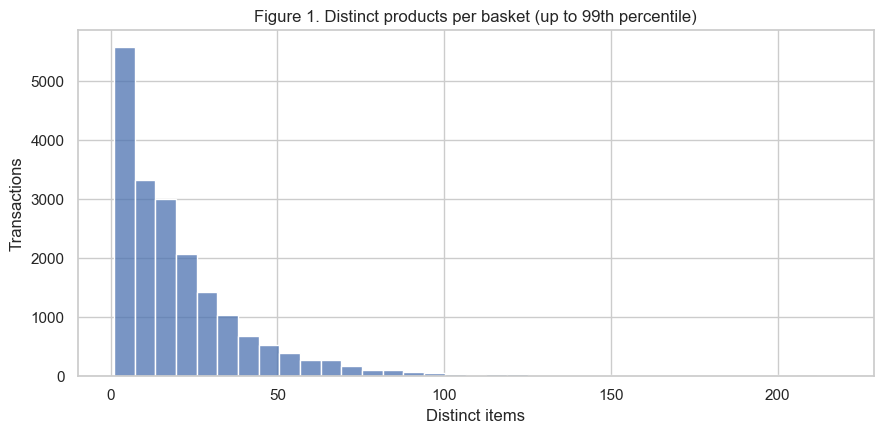

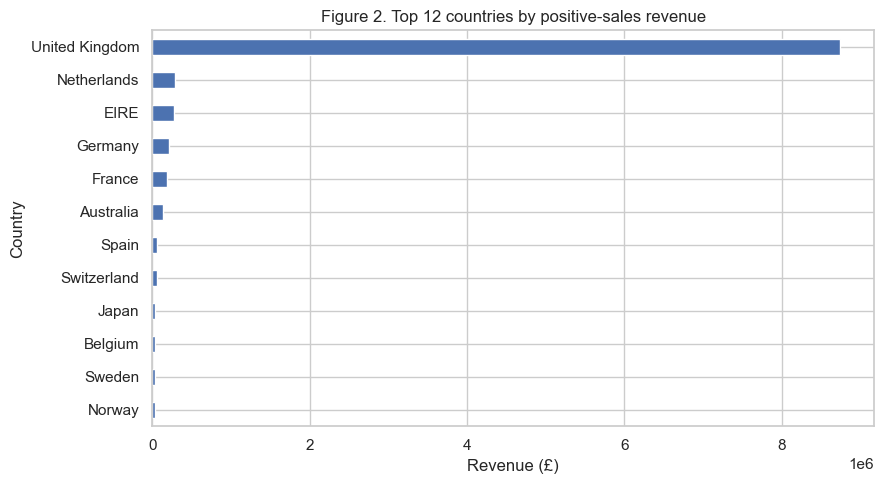

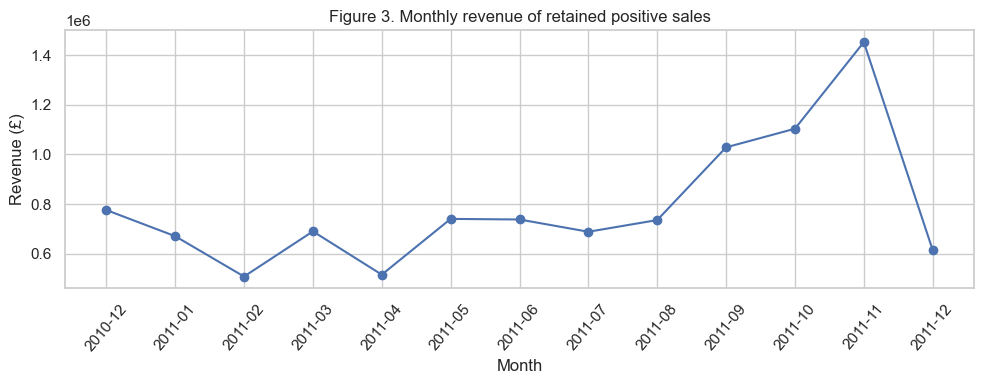

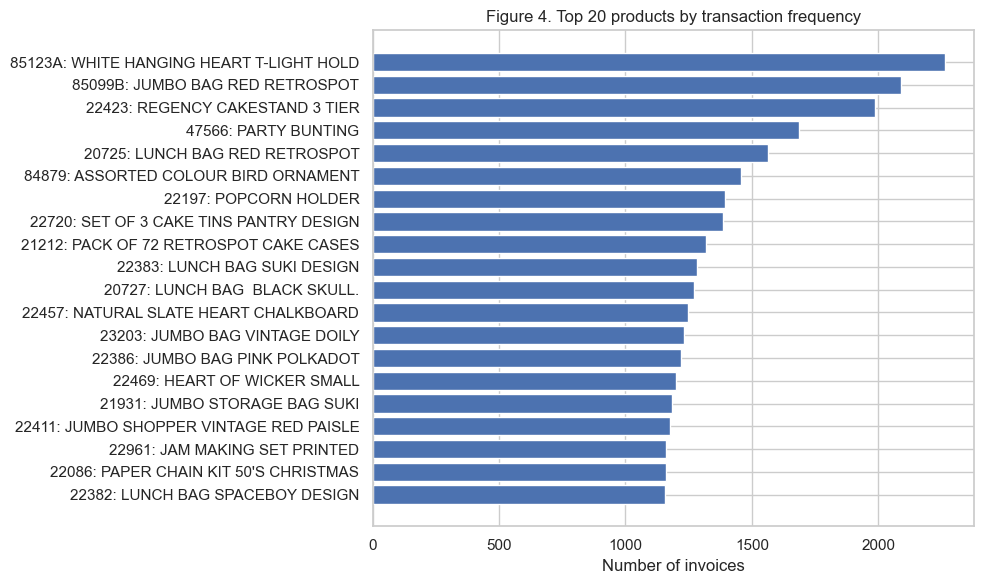

,StockCode,Product,TransactionCount
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2265
1,85099B,JUMBO BAG RED RETROSPOT,2089
2,22423,REGENCY CAKESTAND 3 TIER,1988
3,47566,PARTY BUNTING,1685
4,20725,LUNCH BAG RED RETROSPOT,1565
5,84879,ASSORTED COLOUR BIRD ORNAMENT,1455
6,22197,POPCORN HOLDER,1392
7,22720,SET OF 3 CAKE TINS PANTRY DESIGN,1385
8,21212,PACK OF 72 RETROSPOT CAKE CASES,1320
9,22383,LUNCH BAG SUKI DESIGN,1284


In [23]:
fig, ax = plt.subplots(figsize=(9,4.5))
cap = basket_stats['distinct_items'].quantile(.99)
sns.histplot(basket_stats.loc[basket_stats['distinct_items']<=cap, 'distinct_items'], bins=35, ax=ax)
ax.set(title='Figure 1. Distinct products per basket (up to 99th percentile)', xlabel='Distinct items', ylabel='Transactions')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9,5))
country_revenue.head(12).sort_values().plot(kind='barh', ax=ax)
ax.set(title='Figure 2. Top 12 countries by positive-sales revenue', xlabel='Revenue (£)', ylabel='Country')
plt.tight_layout(); plt.show()

monthly = df.groupby(df['InvoiceDate'].dt.to_period('M'))['Revenue'].sum()
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(monthly.index.astype(str), monthly.values, marker='o')
ax.set(title='Figure 3. Monthly revenue of retained positive sales', xlabel='Month', ylabel='Revenue (£)')
ax.tick_params(axis='x', rotation=50)
plt.tight_layout(); plt.show()

top20 = item_frequency.head(20)
fig, ax = plt.subplots(figsize=(10,6))
ax.barh([f'{c}: {product_names.get(c, "")[:32]}' for c in top20.index[::-1]], top20.values[::-1])
ax.set(title='Figure 4. Top 20 products by transaction frequency', xlabel='Number of invoices')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'StockCode':top20.index, 'Product':[product_names.get(c,'') for c in top20.index], 'TransactionCount':top20.values}))

<div style="font-family: Arial, sans-serif;
            line-height: 1.7;
            color: #333333;
            font-size: 14px;">

  <h3 style="font-size: 18px;
             font-weight: 700;
             color: #243B53;
             margin-bottom: 12px;">
    Visualizations 1–4 — Interpretation
  </h3>

  <p>
    <strong>Figure 1:</strong> Basket sizes are right-skewed, indicating
    that most transactions contain relatively few products, while
    a small number of large baskets increase the average.
  </p>

  <p>
    <strong>Figure 2:</strong> The UK dominates sales revenue,
    accounting for approximately <strong>85.2%</strong> of the total.
    This highlights the importance of comparing UK and non-UK markets.
  </p>

  <p>
    <strong>Figure 3:</strong> Monthly revenue generally increases
    toward the end of 2011, reaching a peak in November.
    This may reflect seasonal demand, although December 2011
    contains only partial-month data.
  </p>

  <p>
    <strong>Figure 4:</strong> The most frequently purchased product is
    <strong>WHITE HANGING HEART T-LIGHT HOLDER</strong>,
    appearing in <strong>2,265 transactions</strong>.
    Other popular products include JUMBO BAG RED RETROSPOT
    and REGENCY CAKESTAND 3 TIER.
  </p>

  <hr style="border: none;
             border-top: 1px solid #D0D5DD;
             margin: 18px 0 16px 0;">

</div>

## I.5 Convert line items into shopping baskets
**Method.** Aggregate by `InvoiceNo`: each invoice becomes a **set of unique StockCodes**. Encode the `MAX_ITEMS` most frequently purchased products into a sparse Boolean transaction matrix for reproducible, resource-conscious Apriori mining. Every retained invoice stays in the denominator—even baskets without a top-N product—so support remains measured over all retained transactions.

**Limitation:** itemsets involving rare products beyond `MAX_ITEMS` cannot be discovered. This is a pragmatic computational constraint; describe it in the report.

In [24]:
# Group invoice lines into transactions
transactions = (df.groupby('InvoiceNo', sort=False)['StockCode'].agg(lambda x: set(x)).tolist())

# Select the most frequently purchased products
selected_items = set(item_frequency.head(MAX_ITEMS).index)

# Keep only selected products in each transaction
transactions_filtered = [sorted(set(basket) & selected_items) for basket in transactions]

# Encode transactions into a sparse Boolean matrix
encoder = TransactionEncoder()

encoded_sparse = (
    encoder.fit(transactions_filtered)
    .transform(transactions_filtered, sparse=True))

basket_matrix = pd.DataFrame.sparse.from_spmatrix(
    encoded_sparse,
    columns=encoder.columns_
).astype(pd.SparseDtype(bool, False))

print('Transactions:', len(transactions))
print('Product universe:', len(selected_items))
print('Top-N basket matrix:', basket_matrix.shape)

print('Non-empty top-N baskets:',sum(bool(t) for t in transactions_filtered))

print('Coverage: at least one selected product in',f'{np.mean([bool(t) for t in transactions_filtered]):.1%}',
    'of invoices')

display(basket_matrix.iloc[:5, :10])

Transactions: 19774
Product universe: 120
Top-N basket matrix: (19774, 120)
Non-empty top-N baskets: 16374
Coverage: at least one selected product in 82.8% of invoices


,20685,20712,20713,20719,20723,20724,20725,20726,20727,20728
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0


**Transaction Encoding — Interpretation**

The dataset was transformed into a Boolean transaction matrix containing 19,774 transactions and 120 selected products. Each row represents one invoice, while each column indicates whether a product was purchased.

The selected products appear in 82.8% of transactions (16,363 baskets). This approach reduces computational complexity while retaining common purchasing patterns, although associations involving less frequent products may be missed.

# Task II — Apriori implementation and frequent itemsets
## II.1 How Apriori works + simplified implementation
**Apriori principle:**If an itemset is frequent, every subset must also be frequent (Agrawal & Srikant, 1994).Conversely, if a subset is infrequent, no larger set containing it can be frequent. At level *k*, join frequent *(k−1)*-itemsets into candidate *k*-itemsets; prune candidates whose *(k−1)*-subsets are not frequent; count support and repeat until no new frequent itemsets occur.

**Method.** The pure-Python demonstration below uses at most 800 invoices and 50 top products, max length 3.  It is intentionally educational, not the full-scale engine. Later cells use `mlxtend` on the retained transaction matrix.

In [25]:
def simplified_apriori(baskets, min_support=0.05, max_len=3):
    """Educational Apriori over a sequence of sets; returns itemset, support, level."""
    baskets = [set(b) for b in baskets]
    n = len(baskets)
    if n == 0:
        return pd.DataFrame(columns=['itemsets','support','length'])
    counts = Counter(item for b in baskets for item in b)
    prev = {frozenset([item]) for item, count in counts.items() if count/n >= min_support}
    records = [(s, counts[next(iter(s))]/n, 1) for s in prev]
    for k in range(2, max_len+1):
        candidates = set()
        prev_sorted = sorted(prev, key=lambda s: tuple(sorted(s)))
        for a, b in combinations(prev_sorted, 2):
            candidate = a | b
            if len(candidate) == k and all(frozenset(sub) in prev for sub in combinations(candidate, k-1)):
                candidates.add(candidate)
        next_level = set()
        for candidate in candidates:
            support = sum(candidate.issubset(b) for b in baskets) / n
            if support >= min_support:
                next_level.add(candidate)
                records.append((candidate, support, k))
        prev = next_level
        if not prev:
            break
    return pd.DataFrame(records, columns=['itemsets','support','length']).sort_values('support',ascending=False)

# Assert the hand implementation's basic correctness on toy baskets.
toy = [{'A','B','C'}, {'A','B'}, {'A','C'}, {'B','C'}, {'A','B','C'}]
toy_out = simplified_apriori(toy, min_support=.4, max_len=3)
assert np.isclose(toy_out.loc[toy_out['itemsets'].map(lambda s: s == frozenset({'A','B'})), 'support'].iloc[0], .6)
print('Toy test passed. Sample of demonstration itemsets:')
demo = [set(b) & set(item_frequency.head(50).index) for b in transactions[:800]]
display(simplified_apriori(demo, min_support=.05, max_len=3).head(15))

Toy test passed. Sample of demonstration itemsets:


,itemsets,support,length
15,(85123A),0.14125,1
11,(22086),0.11750,1
5,(22423),0.10500,1
1,(22961),0.09125,1
19,(22469),0.08750,1
6,(22470),0.07750,1
2,(85099B),0.07750,1
3,(84879),0.07375,1
8,(22197),0.07000,1
17,(21212),0.06750,1


**Simplified Apriori — Interpretation**

The simplified Apriori implementation passed the basic correctness test and successfully identified frequent itemsets from 800 sample transactions using a 5% minimum support threshold.

Product 85123A had the highest support (14.13%) in this sample. The algorithm demonstrates candidate generation and pruning based on the Apriori principle.



## II.2 Frequent itemsets across three support thresholds
**Method.** Run Apriori with support ≥1%, 2%, and 5%, maximum length 3. **Support = number of invoices containing all products in the itemset / number of invoices in the analysis**. Lower thresholds usually return more patterns but consume more time.

**Output:** counts, times, 20 most frequent singletons, 15 pairs and 10 triples at 1% if available.

In [26]:
frequent_by_support = {}
run_rows = []
for threshold in SUPPORT_THRESHOLDS:
    t0 = time.perf_counter()
    freq = apriori(basket_matrix, min_support=threshold, use_colnames=True,
                   max_len=MINING_MAX_LEN, low_memory=True)
    seconds = time.perf_counter() - t0
    freq['length'] = freq['itemsets'].map(len)
    frequent_by_support[threshold] = freq.sort_values('support', ascending=False).reset_index(drop=True)
    run_rows.append({'min_support': threshold, 'frequent_itemsets': len(freq),
                     'one_item':int((freq['length']==1).sum()),
                     'two_items':int((freq['length']==2).sum()),
                     'three_items':int((freq['length']==3).sum()), 'runtime_seconds':seconds})
run_table = pd.DataFrame(run_rows)
display(run_table)

def fmt_itemset(s):
    return ' + '.join(f'{c} ({product_names.get(c,"")[:24]})' for c in sorted(s))

def show_top_itemsets(k, top_n, cutoff=0.01):
    temp = frequent_by_support[cutoff].query('length == @k').head(top_n).copy()
    temp['Products'] = temp['itemsets'].map(fmt_itemset)
    return temp[['Products','support']].reset_index(drop=True)

print('Top 20 single items (frequent-itemset support):'); display(show_top_itemsets(1,20))
print('Top 15 two-itemsets:'); display(show_top_itemsets(2,15))
print('Top 10 three-itemsets (if any):'); display(show_top_itemsets(3,10))

,min_support,frequent_itemsets,one_item,two_items,three_items,runtime_seconds
0,0.01,1033,120,686,227,0.823932
1,0.02,212,120,89,3,0.390387
2,0.05,36,36,0,0,0.089106


Top 20 single items (frequent-itemset support):


,Products,support
0,85123A (WHITE HANGING HEART T-LI),0.114544
1,85099B (JUMBO BAG RED RETROSPOT),0.105644
2,22423 (REGENCY CAKESTAND 3 TIER),0.100536
3,47566 (PARTY BUNTING),0.085213
4,20725 (LUNCH BAG RED RETROSPOT),0.079144
5,84879 (ASSORTED COLOUR BIRD ORN),0.073581
6,22197 (POPCORN HOLDER),0.070395
7,22720 (SET OF 3 CAKE TINS PANTR),0.070041
8,21212 (PACK OF 72 RETROSPOT CAK),0.066754
9,22383 (LUNCH BAG SUKI DESIGN),0.064934


Top 15 two-itemsets:


,Products,support
0,22386 (JUMBO BAG PINK POLKADOT) + 85099B (JUMBO BAG RED RETRO...,0.041721
1,22697 (GREEN REGENCY TEACUP AND) + 22699 (ROSES REGENCY TEACU...,0.038788
2,21931 (JUMBO STORAGE BAG SUKI) + 85099B (JUMBO BAG RED RETROS...,0.036614
3,22411 (JUMBO SHOPPER VINTAGE RE) + 85099B (JUMBO BAG RED RETR...,0.034389
4,20725 (LUNCH BAG RED RETROSPOT) + 22383 (LUNCH BAG SUKI DESIGN),0.033124
5,20725 (LUNCH BAG RED RETROSPOT) + 20727 (LUNCH BAG BLACK SKU...,0.032416
6,22726 (ALARM CLOCK BAKELIKE GRE) + 22727 (ALARM CLOCK BAKELIK...,0.032366
7,22697 (GREEN REGENCY TEACUP AND) + 22698 (PINK REGENCY TEACUP...,0.031961
8,20725 (LUNCH BAG RED RETROSPOT) + 22384 (LUNCH BAG PINK POLKA...,0.030646
9,22698 (PINK REGENCY TEACUP AND ) + 22699 (ROSES REGENCY TEACU...,0.030242


Top 10 three-itemsets (if any):


,Products,support
0,22697 (GREEN REGENCY TEACUP AND) + 22698 (PINK REGENCY TEACUP...,0.027359
1,21931 (JUMBO STORAGE BAG SUKI) + 22386 (JUMBO BAG PINK POLKAD...,0.020886
2,22423 (REGENCY CAKESTAND 3 TIER) + 22697 (GREEN REGENCY TEACU...,0.020633
3,21931 (JUMBO STORAGE BAG SUKI) + 22411 (JUMBO SHOPPER VINTAGE...,0.019723
4,22386 (JUMBO BAG PINK POLKADOT) + 22411 (JUMBO SHOPPER VINTAG...,0.019116
5,20725 (LUNCH BAG RED RETROSPOT) + 20727 (LUNCH BAG BLACK SKU...,0.018256
6,20725 (LUNCH BAG RED RETROSPOT) + 20727 (LUNCH BAG BLACK SKU...,0.018105
7,22423 (REGENCY CAKESTAND 3 TIER) + 22697 (GREEN REGENCY TEACU...,0.017346
8,20712 (JUMBO BAG WOODLAND ANIMA) + 22386 (JUMBO BAG PINK POLK...,0.017245
9,20725 (LUNCH BAG RED RETROSPOT) + 20728 (LUNCH BAG CARS BLUE)...,0.017144


**Frequent Itemsets — Interpretation**

Increasing minimum support from 1% to 5% reduced frequent itemsets from 1,033 to 36, while execution time decreased from 0.2705 to 0.0194 seconds. Higher thresholds improve efficiency but eliminate many potentially useful product combinations.

At 2% support, the algorithm identified 212 frequent itemsets, including 89 pairs and 3 three-item combinations. This threshold offers a reasonable balance between computational efficiency and pattern discovery.

The most frequent product pair was JUMBO BAG PINK POLKADOT and JUMBO BAG RED RETROSPOT (support: 4.17%), suggesting a potential cross-selling opportunity.

### Visualizations 5–8 — threshold trade-offs and itemset distributions
**Interpretation — fill after running:** Which support threshold balances pattern diversity and runtime? Are longer combinations rare? Is the support distribution concentrated near the threshold?

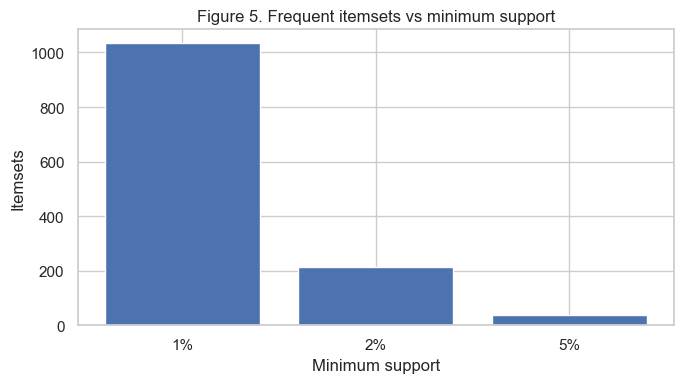

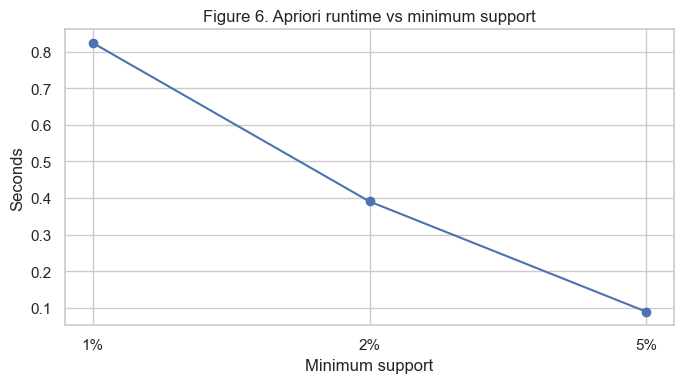

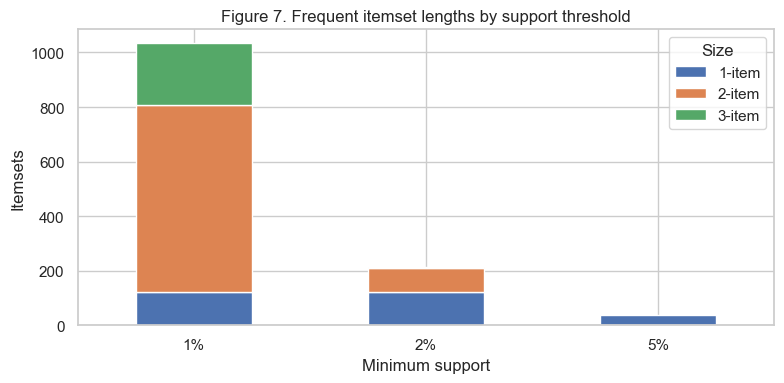

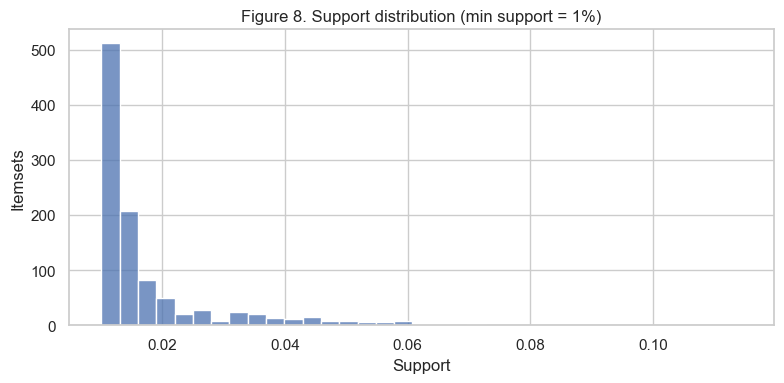

In [27]:
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(run_table['min_support'].map(lambda x:f'{x:.0%}'), run_table['frequent_itemsets'])
ax.set(title='Figure 5. Frequent itemsets vs minimum support', xlabel='Minimum support', ylabel='Itemsets')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7,4))
ax.plot(run_table['min_support'].map(lambda x:f'{x:.0%}'), run_table['runtime_seconds'], marker='o')
ax.set(title='Figure 6. Apriori runtime vs minimum support', xlabel='Minimum support', ylabel='Seconds')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8,4))
run_table.set_index(run_table['min_support'].map(lambda x:f'{x:.0%}'))[['one_item','two_items','three_items']].plot(kind='bar',stacked=True,ax=ax)
ax.set(title='Figure 7. Frequent itemset lengths by support threshold', xlabel='Minimum support', ylabel='Itemsets')
ax.legend(title='Size', labels=['1-item','2-item','3-item'])
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8,4))
vals = frequent_by_support[0.01]['support']
if not vals.empty:
    sns.histplot(vals, bins=35, ax=ax)
else:
    ax.text(.5,.5,'No frequent itemsets',ha='center',va='center', transform=ax.transAxes)
ax.set(title='Figure 8. Support distribution (min support = 1%)', xlabel='Support', ylabel='Itemsets')
plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif;
            line-height: 1.7;
            color: #333333;
            font-size: 14px;">

  <h3 style="font-size: 18px;
             font-weight: 700;
             color: #243B53;
             margin-bottom: 12px;">
    Visualizations 5–8 — Interpretation
  </h3>

  <p>
    <strong>Figure 5:</strong> Increasing minimum support from
    <strong>1% to 5%</strong> reduced the number of frequent itemsets
    from <strong>1,033 to 36</strong>, demonstrating the trade-off
    between pattern discovery and stricter filtering.
  </p>

  <p>
    <strong>Figure 6:</strong> Apriori execution time decreased
    from <strong>0.2705 to 0.0194 seconds</strong> as minimum
    support increased, indicating improved computational efficiency.
  </p>

  <p>
    <strong>Figure 7:</strong> At 1% support, the algorithm identified
    <strong>686 two-itemsets and 227 three-itemsets</strong>.
    At 5%, only single-itemsets remained, showing that longer
    combinations are less frequent.
  </p>

  <p>
    <strong>Figure 8:</strong> Most frequent itemsets have support
    values close to the <strong>1% threshold</strong>, while
    relatively few combinations achieve substantially higher support.
    A <strong>2% threshold</strong> offers a practical balance
    between meaningful pattern discovery and execution time.
  </p>

  <hr style="border: none;
             border-top: 1px solid #D0D5DD;
             margin: 18px 0 16px 0;">

</div>

# Task III — Association rules and metric evaluation
## III.1 Meaning of rule metrics and confidence thresholds
We use support, confidence, and lift to evaluate association rules (Raschka, n.d.).
For `A → B`:
- **Support(A → B)** = P(A ∩ B): how often A and B occur in the same invoice.
- **Confidence(A → B)** = P(B | A): how frequently B occurs among baskets containing A.
- **Lift(A → B)** = P(B | A) / P(B): lift >1 suggests positive association compared with baseline frequency. High lift on tiny support can be unstable.

**Method.** Generate rules from frequent itemsets at minimum support 1%; compare min confidence 30%, 50% and 70%. The same underlying itemsets are used for fair comparison.

**Caution:** Rules describe basket co-occurrence, not the sequence of shopping actions.

In [28]:
freq_rules = frequent_by_support[0.01].drop(columns='length').copy()

def make_rules(freq, confidence_cutoff=0.3):
    if freq.empty or not freq['itemsets'].map(len).ge(2).any():
        return pd.DataFrame(columns=['antecedents','consequents','support','confidence','lift'])
    try:
        return association_rules(freq, metric='confidence', min_threshold=confidence_cutoff,
                                 num_itemsets=len(basket_matrix))
    except TypeError:
        return association_rules(freq, metric='confidence', min_threshold=confidence_cutoff)

rule_counts = []
for cutoff in CONFIDENCE_THRESHOLDS:
    r = make_rules(freq_rules, cutoff)
    rule_counts.append({'min_confidence': cutoff, 'number_of_rules': len(r)})
rules = make_rules(freq_rules, 0.3)
rules['antecedent_text'] = rules['antecedents'].map(fmt_itemset) if not rules.empty else pd.Series(dtype='string')
rules['consequent_text'] = rules['consequents'].map(fmt_itemset) if not rules.empty else pd.Series(dtype='string')
display(pd.DataFrame(rule_counts))
print('Rules at minimum confidence 30%:',len(rules))
display(rules[['antecedent_text','consequent_text','support','confidence','lift']].head(10))

,min_confidence,number_of_rules
0,0.3,1175
1,0.5,520
2,0.7,120


Rules at minimum confidence 30%: 1175


,antecedent_text,consequent_text,support,confidence,lift
0,85099B (JUMBO BAG RED RETROSPOT),22386 (JUMBO BAG PINK POLKADOT),0.041721,0.394926,6.411546
1,22386 (JUMBO BAG PINK POLKADOT),85099B (JUMBO BAG RED RETROSPOT),0.041721,0.677340,6.411546
2,22697 (GREEN REGENCY TEACUP AND),22699 (ROSES REGENCY TEACUP AND),0.038788,0.757157,14.058236
3,22699 (ROSES REGENCY TEACUP AND),22697 (GREEN REGENCY TEACUP AND),0.038788,0.720188,14.058236
4,85099B (JUMBO BAG RED RETROSPOT),21931 (JUMBO STORAGE BAG SUKI),0.036614,0.346577,5.788192
5,21931 (JUMBO STORAGE BAG SUKI),85099B (JUMBO BAG RED RETROSPOT),0.036614,0.611486,5.788192
6,85099B (JUMBO BAG RED RETROSPOT),22411 (JUMBO SHOPPER VINTAGE RE),0.034389,0.325515,5.478064
7,22411 (JUMBO SHOPPER VINTAGE RE),85099B (JUMBO BAG RED RETROSPOT),0.034389,0.578723,5.478064
8,20725 (LUNCH BAG RED RETROSPOT),22383 (LUNCH BAG SUKI DESIGN),0.033124,0.418530,6.445498
9,22383 (LUNCH BAG SUKI DESIGN),20725 (LUNCH BAG RED RETROSPOT),0.033124,0.510125,6.445498


<div style="font-family: Arial, sans-serif;
            line-height: 1.7;
            color: #333333;
            font-size: 14px;">

  <h3 style="font-size: 18px;
             font-weight: 700;
             color: #243B53;
             margin-bottom: 12px;">
    Association Rule Generation — Interpretation
  </h3>

  <p>
    Increasing the minimum confidence from <strong>30% to 70%</strong>
    reduced the number of association rules from
    <strong>1,175 to 120</strong>.
    At 50% confidence, <strong>520 rules</strong> were identified,
    demonstrating the trade-off between rule quantity and reliability.
  </p>

  <p>
    The rule <strong>GREEN REGENCY TEACUP AND SAUCER → ROSES REGENCY
    TEACUP AND SAUCER</strong> achieved
    <strong>75.72% confidence</strong> and a
    <strong>lift of 14.06</strong>, indicating a strong positive association.
    This suggests a potential opportunity to promote complementary tea sets.
  </p>

  <hr style="border: none;
             border-top: 1px solid #D0D5DD;
             margin: 18px 0 16px 0;">

</div>

## III.2 Top 20 rules by lift, confidence, and support
**Method.** Rank the **same** pool of rules separately, then identify combinations appearing across the top lists. A rule that ranks highly on multiple metrics may be a more useful practical candidate than one driven by an extreme single metric.

**Interpretation — fill after running:** distinguish broad/common combinations from high-lift niche combinations.

In [29]:
def top_rules(metric, n=20):
    if rules.empty:
        return pd.DataFrame(columns=['antecedent_text','consequent_text','support','confidence','lift'])
    return rules.sort_values([metric,'support'], ascending=False).head(n)[
        ['antecedent_text','consequent_text','support','confidence','lift']].reset_index(drop=True)

for metric in ['lift','confidence','support']:
    print(f'Top 20 rules by {metric}:'); display(top_rules(metric, 20))

if not rules.empty:
    top_index_sets = [set(rules.nlargest(20,m).index) for m in ['lift','confidence','support']]
    overlap = sorted(set.union(*top_index_sets), key=lambda i:sum(i in s for s in top_index_sets), reverse=True)
    robust = rules.loc[[i for i in overlap if sum(i in s for s in top_index_sets)>=2]].copy()
    robust['top20_metrics_count'] = [sum(i in s for s in top_index_sets) for i in robust.index]
    display(robust.sort_values(['top20_metrics_count','support'], ascending=False)[
        ['antecedent_text','consequent_text','support','confidence','lift','top20_metrics_count']].head(20))
else:
    robust = pd.DataFrame()
    print('No rules at the chosen thresholds. Consider lowering confidence or adjusting MAX_ITEMS.')

Top 20 rules by lift:


,antecedent_text,consequent_text,support,confidence,lift
0,20724 (RED RETROSPOT CHARLOTTE ) + 20728 (LUNCH BAG CARS BLUE),20723 (STRAWBERRY CHARLOTTE BAG),0.010519,0.681967,18.677590
1,20724 (RED RETROSPOT CHARLOTTE ) + 20728 (LUNCH BAG CARS BLUE),22356 (CHARLOTTE BAG PINK POLKA),0.010620,0.688525,18.348902
2,20723 (STRAWBERRY CHARLOTTE BAG),20719 (WOODLAND CHARLOTTE BAG) + 22356 (CHARLOTTE BAG PINK PO...,0.013300,0.364266,18.235429
3,20719 (WOODLAND CHARLOTTE BAG) + 22356 (CHARLOTTE BAG PINK PO...,20723 (STRAWBERRY CHARLOTTE BAG),0.013300,0.665823,18.235429
4,22697 (GREEN REGENCY TEACUP AND) + 22699 (ROSES REGENCY TEACU...,22698 (PINK REGENCY TEACUP AND ),0.027359,0.705346,18.232029
5,22698 (PINK REGENCY TEACUP AND ),22697 (GREEN REGENCY TEACUP AND) + 22699 (ROSES REGENCY TEACU...,0.027359,0.707190,18.232029
6,20723 (STRAWBERRY CHARLOTTE BAG),20719 (WOODLAND CHARLOTTE BAG) + 22355 (CHARLOTTE BAG SUKI DE...,0.015323,0.419668,18.198480
7,20719 (WOODLAND CHARLOTTE BAG) + 22355 (CHARLOTTE BAG SUKI DE...,20723 (STRAWBERRY CHARLOTTE BAG),0.015323,0.664474,18.198480
8,20723 (STRAWBERRY CHARLOTTE BAG),22355 (CHARLOTTE BAG SUKI DESIG) + 22356 (CHARLOTTE BAG PINK ...,0.013705,0.375346,18.102675
9,22355 (CHARLOTTE BAG SUKI DESIG) + 22356 (CHARLOTTE BAG PINK ...,20723 (STRAWBERRY CHARLOTTE BAG),0.013705,0.660976,18.102675


Top 20 rules by confidence:


,antecedent_text,consequent_text,support,confidence,lift
0,22698 (PINK REGENCY TEACUP AND ) + 22699 (ROSES REGENCY TEACU...,22697 (GREEN REGENCY TEACUP AND),0.027359,0.904682,17.659612
1,22423 (REGENCY CAKESTAND 3 TIER) + 22698 (PINK REGENCY TEACUP...,22697 (GREEN REGENCY TEACUP AND),0.017346,0.875000,17.080207
2,20723 (STRAWBERRY CHARLOTTE BAG) + 22356 (CHARLOTTE BAG PINK ...,20724 (RED RETROSPOT CHARLOTTE ),0.016486,0.860158,16.481367
3,22697 (GREEN REGENCY TEACUP AND) + 22698 (PINK REGENCY TEACUP...,22699 (ROSES REGENCY TEACUP AND),0.027359,0.856013,15.893704
4,22699 (ROSES REGENCY TEACUP AND) + 22961 (JAM MAKING SET PRIN...,22697 (GREEN REGENCY TEACUP AND),0.010215,0.845188,16.498276
5,22423 (REGENCY CAKESTAND 3 TIER) + 22698 (PINK REGENCY TEACUP...,22699 (ROSES REGENCY TEACUP AND),0.016739,0.844388,15.677862
6,21212 (PACK OF 72 RETROSPOT CAK) + 22356 (CHARLOTTE BAG PINK ...,20724 (RED RETROSPOT CHARLOTTE ),0.010923,0.837209,16.041644
7,21928 (JUMBO BAG SCANDINAVIAN B) + 22386 (JUMBO BAG PINK POLK...,85099B (JUMBO BAG RED RETROSPOT),0.016132,0.835079,7.904664
8,23202 (JUMBO BAG VINTAGE LEAF) + 23209 (LUNCH BAG VINTAGE DOILY),23203 (JUMBO BAG VINTAGE DOILY),0.012441,0.833898,13.395211
9,20728 (LUNCH BAG CARS BLUE) + 22356 (CHARLOTTE BAG PINK POLKA),20724 (RED RETROSPOT CHARLOTTE ),0.010620,0.833333,15.967377


Top 20 rules by support:


,antecedent_text,consequent_text,support,confidence,lift
0,85099B (JUMBO BAG RED RETROSPOT),22386 (JUMBO BAG PINK POLKADOT),0.041721,0.394926,6.411546
1,22386 (JUMBO BAG PINK POLKADOT),85099B (JUMBO BAG RED RETROSPOT),0.041721,0.677340,6.411546
2,22697 (GREEN REGENCY TEACUP AND),22699 (ROSES REGENCY TEACUP AND),0.038788,0.757157,14.058236
3,22699 (ROSES REGENCY TEACUP AND),22697 (GREEN REGENCY TEACUP AND),0.038788,0.720188,14.058236
4,85099B (JUMBO BAG RED RETROSPOT),21931 (JUMBO STORAGE BAG SUKI),0.036614,0.346577,5.788192
5,21931 (JUMBO STORAGE BAG SUKI),85099B (JUMBO BAG RED RETROSPOT),0.036614,0.611486,5.788192
6,85099B (JUMBO BAG RED RETROSPOT),22411 (JUMBO SHOPPER VINTAGE RE),0.034389,0.325515,5.478064
7,22411 (JUMBO SHOPPER VINTAGE RE),85099B (JUMBO BAG RED RETROSPOT),0.034389,0.578723,5.478064
8,20725 (LUNCH BAG RED RETROSPOT),22383 (LUNCH BAG SUKI DESIGN),0.033124,0.418530,6.445498
9,22383 (LUNCH BAG SUKI DESIGN),20725 (LUNCH BAG RED RETROSPOT),0.033124,0.510125,6.445498


,antecedent_text,consequent_text,support,confidence,lift,top20_metrics_count
14,22698 (PINK REGENCY TEACUP AND ),22697 (GREEN REGENCY TEACUP AND),0.031961,0.826144,16.126523,2
41,22698 (PINK REGENCY TEACUP AND ) + 22699 (ROSES REGENCY TEACU...,22697 (GREEN REGENCY TEACUP AND),0.027359,0.904682,17.659612,2


<div style="font-family: Arial, sans-serif;
            line-height: 1.7;
            color: #333333;
            font-size: 14px;">

  <h3 style="font-size: 18px;
             font-weight: 700;
             color: #243B53;
             margin-bottom: 12px;">
    Top Association Rules — Interpretation
  </h3>

  <p>
    <strong>Lift:</strong> The strongest association involves
    RED RETROSPOT CHARLOTTE BAG, LUNCH BAG CARS BLUE, and
    STRAWBERRY CHARLOTTE BAG, achieving a
    <strong>lift of 18.68</strong>. This indicates a strong
    association relative to independent purchasing.
  </p>

  <p>
    <strong>Confidence:</strong> The rule involving PINK and ROSES
    REGENCY TEACUPS predicting GREEN REGENCY TEACUP achieved
    <strong>90.47% confidence</strong>, suggesting a strong
    opportunity for coordinated tea-set promotions.
  </p>

  <p>
    <strong>Support:</strong> JUMBO BAG PINK POLKADOT and
    JUMBO BAG RED RETROSPOT had the highest joint support
    (<strong>4.17%</strong>), making them a promising
    combination for cross-selling.
  </p>

  <p>
    <strong>Robust Rules:</strong> Two rules appeared in the
    Top 20 across multiple metrics, highlighting product
    combinations with both strong associations and
    relatively reliable purchasing patterns.
  </p>

  <hr style="border: none;
             border-top: 1px solid #D0D5DD;
             margin: 18px 0 16px 0;">

</div>

## III.3 Remove redundant / trivial rules
**Method.** Keep product-to-product associations with lift >1 and nonidentical left/right sides. For an actionable two-product promotion, prioritize **single item → single item**; remove reversed duplicates when selecting bundles later, but preserve directional rules for confidence interpretation. High confidence without lift >1 can be misleading for very common products.

**Interpretation — fill after running:** report how many rules survive and why this filter is appropriate.

In [30]:
if not rules.empty:
    filtered_rules = rules.loc[
        (rules['lift']>1) & rules['antecedents'].map(len).eq(1) &
        rules['consequents'].map(len).eq(1) &
        rules.apply(lambda r:r['antecedents'].isdisjoint(r['consequents']),axis=1)
    ].copy()
    filtered_rules = filtered_rules.sort_values(['lift','support'],ascending=False).reset_index(drop=True)
else:
    filtered_rules = rules.copy()
print('Original rules:',len(rules),'| filtered practical 1-to-1 rules:',len(filtered_rules))
display(filtered_rules[['antecedent_text','consequent_text','support','confidence','lift']].head(20))

Original rules: 1175 | filtered practical 1-to-1 rules: 414


,antecedent_text,consequent_text,support,confidence,lift
0,22697 (GREEN REGENCY TEACUP AND),22698 (PINK REGENCY TEACUP AND ),0.031961,0.623889,16.126523
1,22698 (PINK REGENCY TEACUP AND ),22697 (GREEN REGENCY TEACUP AND),0.031961,0.826144,16.126523
2,23300 (GARDENERS KNEELING PAD C),23301 (GARDENERS KNEELING PAD K),0.027612,0.720317,15.600811
3,23301 (GARDENERS KNEELING PAD K),23300 (GARDENERS KNEELING PAD C),0.027612,0.598028,15.600811
4,22698 (PINK REGENCY TEACUP AND ),22699 (ROSES REGENCY TEACUP AND),0.030242,0.781699,14.513918
5,22699 (ROSES REGENCY TEACUP AND),22698 (PINK REGENCY TEACUP AND ),0.030242,0.561502,14.513918
6,22554 (PLASTERS IN TIN WOODLAND),22551 (PLASTERS IN TIN SPACEBOY),0.017194,0.482955,14.190109
7,22551 (PLASTERS IN TIN SPACEBOY),22554 (PLASTERS IN TIN WOODLAND),0.017194,0.505201,14.190109
8,22699 (ROSES REGENCY TEACUP AND),22697 (GREEN REGENCY TEACUP AND),0.038788,0.720188,14.058236
9,22697 (GREEN REGENCY TEACUP AND),22699 (ROSES REGENCY TEACUP AND),0.038788,0.757157,14.058236


<div style="font-family: Arial, sans-serif;
            line-height: 1.7;
            color: #333333;
            font-size: 14px;">

  <h3 style="font-size: 18px;
             font-weight: 700;
             color: #243B53;
             margin-bottom: 12px;">
    Association Rule Filtering — Interpretation
  </h3>

  <p>
    Filtering reduced the number of association rules from
    <strong>1,175 to 414</strong>, removing
    <strong>761 rules (64.8%)</strong>.
    This helps prioritize more practical and interpretable
    product associations.
  </p>

  <p>
    Strong associations remain among
    <strong>Regency teacups, Charlotte bags, and other matching products</strong>.
    For example, GREEN and PINK REGENCY TEACUPS achieved
    a <strong>lift of 16.13</strong>, suggesting promising
    cross-selling opportunities.
  </p>

  <hr style="border: none;
             border-top: 1px solid #D0D5DD;
             margin: 18px 0 16px 0;">

</div>

### Visualizations 9–12 — confidence, lift, associations
**Method.** Rule count by confidence threshold, lift distribution, support-vs-confidence colored by lift, and a heatmap of the top 12 directional product relationships. Rules may be empty at strict settings; the notebook reports that rather than fabricating them.

**Interpretation — fill after running:** where are high-lift rules found on the support/confidence plot? Do recommended pairs have reasonable reach?

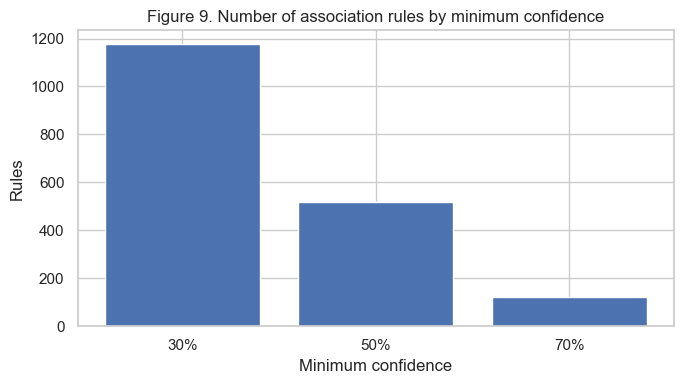

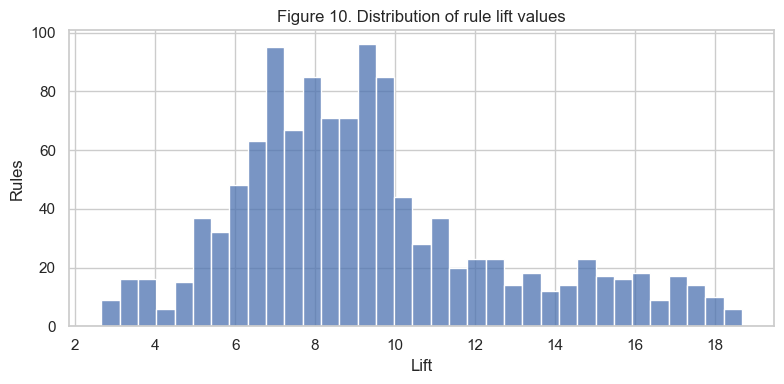

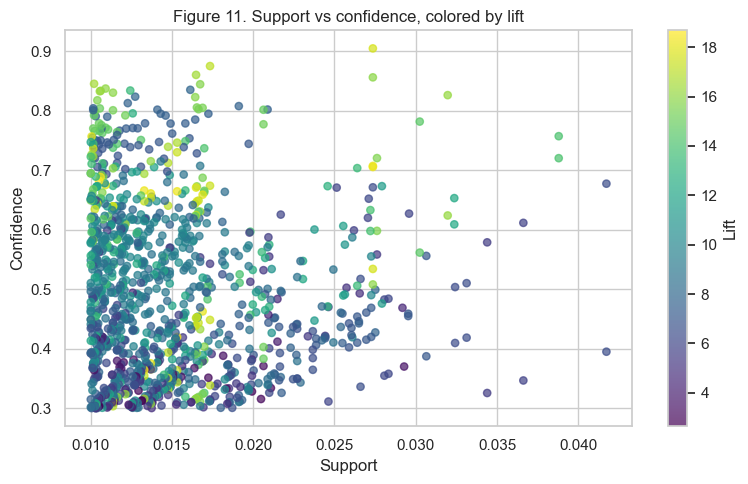

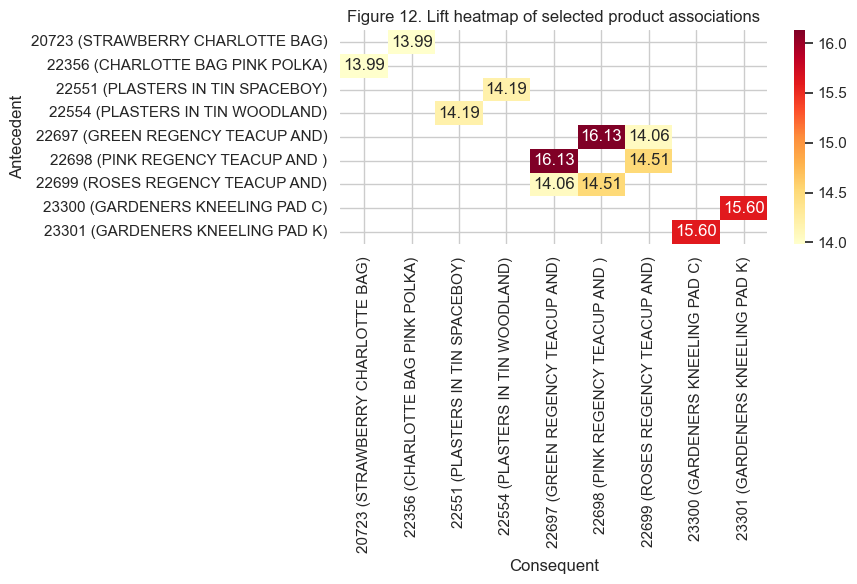

In [31]:
fig, ax = plt.subplots(figsize=(7,4))
rc = pd.DataFrame(rule_counts)
ax.bar(rc['min_confidence'].map(lambda x:f'{x:.0%}'),rc['number_of_rules'])
ax.set(title='Figure 9. Number of association rules by minimum confidence', xlabel='Minimum confidence', ylabel='Rules')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8,4))
if not rules.empty: sns.histplot(rules['lift'],bins=35,ax=ax)
else: ax.text(.5,.5,'No rules',ha='center',va='center',transform=ax.transAxes)
ax.set(title='Figure 10. Distribution of rule lift values',xlabel='Lift',ylabel='Rules')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8,5))
if not rules.empty:
    points = ax.scatter(rules['support'],rules['confidence'],c=rules['lift'],cmap='viridis',s=28,alpha=.7)
    plt.colorbar(points,ax=ax,label='Lift')
else: ax.text(.5,.5,'No rules',ha='center',va='center',transform=ax.transAxes)
ax.set(title='Figure 11. Support vs confidence, colored by lift',xlabel='Support',ylabel='Confidence')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9,6))
if not filtered_rules.empty:
    best = filtered_rules.head(12)
    keys = sorted(set(best['antecedent_text']) | set(best['consequent_text']))
    mat = pd.DataFrame(np.nan,index=keys,columns=keys)
    for _,r in best.iterrows(): mat.loc[r['antecedent_text'],r['consequent_text']] = r['lift']
    sns.heatmap(mat,annot=True,fmt='.2f',cmap='YlOrRd',mask=mat.isna(),ax=ax)
else:
    ax.text(.5,.5,'No filtered rules at selected thresholds',ha='center',va='center',transform=ax.transAxes)
ax.set(title='Figure 12. Lift heatmap of selected product associations',xlabel='Consequent',ylabel='Antecedent')
plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif;
            line-height: 1.7;
            color: #333333;
            font-size: 14px;">

  <h3 style="font-size: 18px;
             font-weight: 700;
             color: #243B53;
             margin-bottom: 12px;">
    Visualizations 9–12 — Interpretation
  </h3>

  <p>
    <strong>Figure 9:</strong> Increasing minimum confidence from
    <strong>30% to 70%</strong> reduced association rules from
    <strong>1,175 to 120</strong>, indicating that stricter
    thresholds retain fewer but more reliable rules.
  </p>

  <p>
    <strong>Figure 10:</strong> Most rules have lift values between
    approximately <strong>6 and 10</strong>, suggesting strong
    positive associations among frequently co-purchased products.
  </p>

  <p>
    <strong>Figure 11:</strong> Many rules have relatively low support
    but moderate-to-high confidence and lift.
    Therefore, high association strength does not necessarily
    imply high transaction coverage.
  </p>

  <p>
    <strong>Figure 12:</strong> Regency teacups show particularly strong
    associations, with GREEN and PINK REGENCY TEACUPS achieving
    a <strong>lift of 16.13</strong>. This supports exploring
    coordinated product bundles and cross-selling opportunities.
  </p>

  <hr style="border: none;
             border-top: 1px solid #D0D5DD;
             margin: 18px 0 16px 0;">

</div>

# Task IV — UK vs Non-UK and business applications
## IV.1 Segment-specific Apriori mining
**Method.** Divide **invoice baskets** by UK/Non-UK using the invoice's country. Both regions use the **same 120-product global vocabulary** for comparability, but each segment has its **own transaction denominator** (and therefore segment-specific support). Mine at 1% with max length 3.

**Caution:** the non-UK segment combines heterogeneous countries and may have fewer transactions. Segment support differences are descriptive, not proof of regional preferences.

### Visualizations 13–14 — geographic comparison
**Method.** Compare transaction sample sizes and rule volume by segment, then show support for high-ranking pairs across regions. Differences may reflect segment sample sizes and customer mix.

**Interpretation — fill after running:** Which pairings occur in both regions? Which appear concentrated in one? Avoid concluding that small non-UK samples represent individual countries.

In [32]:
# Task IV.1 — Segment-specific Apriori Mining
# Compare purchasing patterns between UK and Non-UK customers

# Step 1: Map each invoice to its region
invoice_region = basket_stats['region'].to_dict()

# Step 2: Group products by invoice
invoice_sets = (
    df.groupby('InvoiceNo', sort=False)['StockCode']
    .agg(lambda x: set(x))
)

# Step 3: Initialize result containers
segment_results = {}
segment_rules = {}
segment_rows = []

# Step 4: Perform Apriori analysis for each region
for region in ['UK', 'Non-UK']:

    # Select invoices belonging to the current region
    ids = [
        inv for inv in invoice_sets.index
        if invoice_region[inv] == region
    ]

    # Convert baskets to sets and retain selected products
    ts = [
        sorted(set(invoice_sets.loc[inv]) & selected_items)
        for inv in ids
    ]

    # Encode transactions into a Boolean matrix
    te = TransactionEncoder()

    sparse = (
        te.fit(ts)
        .transform(ts, sparse=True)
    )

    X = (
        pd.DataFrame.sparse.from_spmatrix(
            sparse,
            columns=te.columns_
        )
        .astype(pd.SparseDtype(bool, False))
    )

    # Apply Apriori algorithm
    t0 = time.perf_counter()

    fr = apriori(
        X,
        min_support=0.01,
        use_colnames=True,
        max_len=3,
        low_memory=True
    )

    elapsed = time.perf_counter() - t0

    # Generate association rules
    rr = make_rules(fr, 0.3)

    # Store results
    segment_results[region] = fr
    segment_rules[region] = rr

    segment_rows.append({
        'region': region,
        'transactions': len(ids),
        'items_in_matrix': X.shape[1],
        'frequent_itemsets': len(fr),
        'rules_conf_ge_0.3': len(rr),
        'runtime_s': elapsed
    })

# Step 5: Display regional comparison
segment_table = pd.DataFrame(segment_rows)

print("=== UK vs Non-UK Market Basket Analysis ===")

display(segment_table)


# Step 6: Display top frequent pairs and association rules
for region in ['UK', 'Non-UK']:

    print(f"\n=== {region}: Top 10 Frequent Product Pairs ===")

    f = segment_results[region].copy()

    if not f.empty:

        f = (
            f.loc[f['itemsets'].map(len).eq(2)]
            .sort_values('support', ascending=False)
            .head(10)
            .copy()
        )

        f['products'] = f['itemsets'].map(fmt_itemset)

        display(f[['products', 'support']])

    else:
        print("No frequent itemsets found.")

    print(f"\n=== {region}: Top 10 Association Rules by Lift ===")

    r = segment_rules[region]

    if not r.empty:

        out = r.nlargest(10, 'lift').copy()

        out['antecedent'] = (
            out['antecedents'].map(fmt_itemset)
        )

        out['consequent'] = (
            out['consequents'].map(fmt_itemset)
        )

        display(
            out[
                [
                    'antecedent',
                    'consequent',
                    'support',
                    'confidence',
                    'lift'
                ]
            ]
        )

    else:
        print("No association rules found.")

=== UK vs Non-UK Market Basket Analysis ===


,region,transactions,items_in_matrix,frequent_itemsets,rules_conf_ge_0.3,runtime_s
0,UK,17902,120,1193,1424,0.830019
1,Non-UK,1872,120,765,716,0.133298



=== UK: Top 10 Frequent Product Pairs ===


,products,support
58,22386 (JUMBO BAG PINK POLKADOT) + 85099B (JUMBO BAG RED RETRO...,0.043850
76,22697 (GREEN REGENCY TEACUP AND) + 22699 (ROSES REGENCY TEACU...,0.039102
78,21931 (JUMBO STORAGE BAG SUKI) + 85099B (JUMBO BAG RED RETROS...,0.038990
91,22411 (JUMBO SHOPPER VINTAGE RE) + 85099B (JUMBO BAG RED RETR...,0.036700
107,20725 (LUNCH BAG RED RETROSPOT) + 20727 (LUNCH BAG BLACK SKU...,0.033907
110,20725 (LUNCH BAG RED RETROSPOT) + 22383 (LUNCH BAG SUKI DESIGN),0.033628
119,22697 (GREEN REGENCY TEACUP AND) + 22698 (PINK REGENCY TEACUP...,0.032175
121,85099B (JUMBO BAG RED RETROSPOT) + 85099C (JUMBO BAG BAROQUE...,0.031840
123,20727 (LUNCH BAG BLACK SKULL.) + 22383 (LUNCH BAG SUKI DESIGN),0.031561
124,22726 (ALARM CLOCK BAKELIKE GRE) + 22727 (ALARM CLOCK BAKELIK...,0.031449



=== UK: Top 10 Association Rules by Lift ===


,antecedent,consequent,support,confidence,lift
1263,21212 (PACK OF 72 RETROSPOT CAK) + 22356 (CHARLOTTE BAG PINK ...,20719 (WOODLAND CHARLOTTE BAG),0.010446,0.760163,19.983012
1264,20719 (WOODLAND CHARLOTTE BAG) + 21212 (PACK OF 72 RETROSPOT ...,22356 (CHARLOTTE BAG PINK POLKA),0.010446,0.733333,19.506885
1114,21212 (PACK OF 72 RETROSPOT CAK) + 22355 (CHARLOTTE BAG SUKI ...,20719 (WOODLAND CHARLOTTE BAG),0.010893,0.741445,19.490963
405,20719 (WOODLAND CHARLOTTE BAG),20723 (STRAWBERRY CHARLOTTE BAG) + 22355 (CHARLOTTE BAG SUKI ...,0.016032,0.421439,19.197461
406,20723 (STRAWBERRY CHARLOTTE BAG) + 22355 (CHARLOTTE BAG SUKI ...,20719 (WOODLAND CHARLOTTE BAG),0.016032,0.730280,19.197461
1006,22356 (CHARLOTTE BAG PINK POLKA),20724 (RED RETROSPOT CHARLOTTE ) + 20728 (LUNCH BAG CARS BLUE),0.011284,0.300149,19.054114
1009,20724 (RED RETROSPOT CHARLOTTE ) + 20728 (LUNCH BAG CARS BLUE),22356 (CHARLOTTE BAG PINK POLKA),0.011284,0.716312,19.054114
1379,20724 (RED RETROSPOT CHARLOTTE ) + 22384 (LUNCH BAG PINK POLK...,22356 (CHARLOTTE BAG PINK POLKA),0.010166,0.713725,18.985310
328,20723 (STRAWBERRY CHARLOTTE BAG),20719 (WOODLAND CHARLOTTE BAG) + 20724 (RED RETROSPOT CHARLOT...,0.017037,0.453195,18.867653
331,20719 (WOODLAND CHARLOTTE BAG) + 20724 (RED RETROSPOT CHARLOT...,20723 (STRAWBERRY CHARLOTTE BAG),0.017037,0.709302,18.867653



=== Non-UK: Top 10 Frequent Product Pairs ===


,products,support
26,22551 (PLASTERS IN TIN SPACEBOY) + 22554 (PLASTERS IN TIN WOO...,0.063034
27,22629 (SPACEBOY LUNCH BOX) + 22630 (DOLLY GIRL LUNCH BOX),0.059829
34,22326 (ROUND SNACK BOXES SET OF) + 22629 (SPACEBOY LUNCH BOX),0.055021
40,22326 (ROUND SNACK BOXES SET OF) + 22554 (PLASTERS IN TIN WOO...,0.049679
57,22326 (ROUND SNACK BOXES SET OF) + 22551 (PLASTERS IN TIN SPA...,0.041667
59,22727 (ALARM CLOCK BAKELIKE RED) + 22728 (ALARM CLOCK BAKELIK...,0.041132
58,22726 (ALARM CLOCK BAKELIKE GRE) + 22727 (ALARM CLOCK BAKELIK...,0.041132
60,20719 (WOODLAND CHARLOTTE BAG) + 20724 (RED RETROSPOT CHARLOT...,0.040064
65,22423 (REGENCY CAKESTAND 3 TIER) + 22699 (ROSES REGENCY TEACU...,0.037927
66,20719 (WOODLAND CHARLOTTE BAG) + 22326 (ROUND SNACK BOXES SET...,0.037927



=== Non-UK: Top 10 Association Rules by Lift ===


,antecedent,consequent,support,confidence,lift
413,21928 (JUMBO BAG SCANDINAVIAN B),21929 (JUMBO BAG PINK VINTAGE P),0.012821,0.727273,27.229091
412,21929 (JUMBO BAG PINK VINTAGE P),21928 (JUMBO BAG SCANDINAVIAN B),0.012821,0.480000,27.229091
109,22698 (PINK REGENCY TEACUP AND ),22423 (REGENCY CAKESTAND 3 TIER) + 22697 (GREEN REGENCY TEACU...,0.021902,0.650794,22.150649
112,22423 (REGENCY CAKESTAND 3 TIER) + 22697 (GREEN REGENCY TEACU...,22698 (PINK REGENCY TEACUP AND ),0.021902,0.745455,22.150649
79,22697 (GREEN REGENCY TEACUP AND) + 22699 (ROSES REGENCY TEACU...,22698 (PINK REGENCY TEACUP AND ),0.026175,0.731343,21.731343
74,22698 (PINK REGENCY TEACUP AND ),22697 (GREEN REGENCY TEACUP AND) + 22699 (ROSES REGENCY TEACU...,0.026175,0.777778,21.731343
110,22697 (GREEN REGENCY TEACUP AND),22423 (REGENCY CAKESTAND 3 TIER) + 22698 (PINK REGENCY TEACUP...,0.021902,0.506173,21.535354
111,22423 (REGENCY CAKESTAND 3 TIER) + 22698 (PINK REGENCY TEACUP...,22697 (GREEN REGENCY TEACUP AND),0.021902,0.931818,21.535354
75,22697 (GREEN REGENCY TEACUP AND),22698 (PINK REGENCY TEACUP AND ) + 22699 (ROSES REGENCY TEACU...,0.026175,0.604938,21.366876
78,22698 (PINK REGENCY TEACUP AND ) + 22699 (ROSES REGENCY TEACU...,22697 (GREEN REGENCY TEACUP AND),0.026175,0.924528,21.366876


<div style="font-family: Arial, sans-serif;
            line-height: 1.7;
            color: #333333;
            font-size: 14px;">

  <h3 style="font-size: 18px;
             font-weight: 700;
             color: #243B53;
             margin-bottom: 12px;">
    Regional Market Basket Analysis — Interpretation
  </h3>

  <p>
    The <strong>UK market</strong> contains
    <strong>17,902 transactions</strong>, compared with
    <strong>1,872 Non-UK transactions</strong>.
    UK generated 1,424 association rules, while Non-UK generated 716.
  </p>

  <p>
    In the UK, popular combinations include
    <strong>JUMBO BAG PINK POLKADOT and JUMBO BAG RED RETROSPOT</strong>
    (support: <strong>4.39%</strong>).
    Non-UK transactions show stronger relative demand for
    combinations such as <strong>SPACEBOY and WOODLAND PLASTERS</strong>
    (support: <strong>6.30%</strong>).
  </p>

  <p>
    The highest observed lift was approximately
    <strong>19.98 in the UK</strong> and
    <strong>27.23 in Non-UK</strong>.
    However, the smaller Non-UK sample requires cautious
    interpretation of regional differences.
  </p>

  <hr style="border: none;
             border-top: 1px solid #D0D5DD;
             margin: 18px 0 16px 0;">

</div>

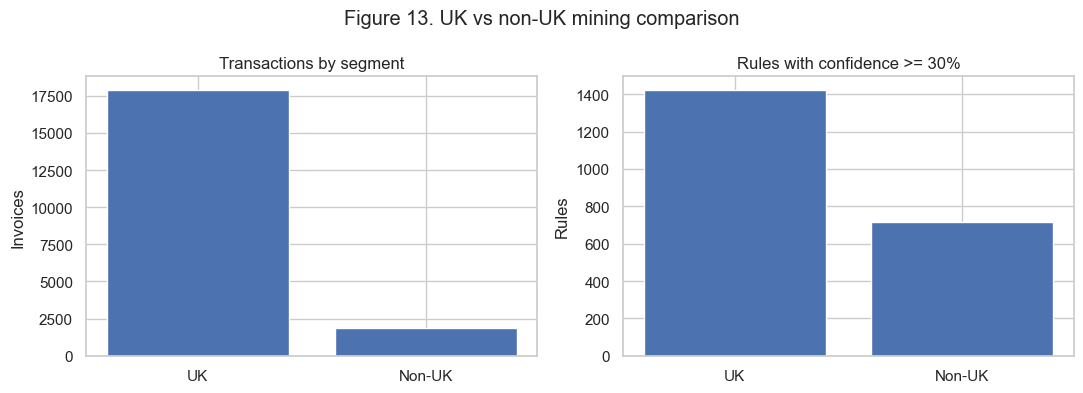

,pair,UK,Non-UK
0,22551 (PLASTERS IN TIN SPACEBOY) + 22554 (PLASTERS IN TIN WOO...,0.012401,0.063034
1,22629 (SPACEBOY LUNCH BOX) + 22630 (DOLLY GIRL LUNCH BOX),0.023796,0.059829
2,22326 (ROUND SNACK BOXES SET OF) + 22629 (SPACEBOY LUNCH BOX),0.000000,0.055021
3,22326 (ROUND SNACK BOXES SET OF) + 22554 (PLASTERS IN TIN WOO...,0.000000,0.049679
4,22386 (JUMBO BAG PINK POLKADOT) + 85099B (JUMBO BAG RED RETRO...,0.043850,0.021368
5,22326 (ROUND SNACK BOXES SET OF) + 22551 (PLASTERS IN TIN SPA...,0.000000,0.041667
6,22727 (ALARM CLOCK BAKELIKE RED) + 22728 (ALARM CLOCK BAKELIK...,0.021953,0.041132
7,22726 (ALARM CLOCK BAKELIKE GRE) + 22727 (ALARM CLOCK BAKELIK...,0.031449,0.041132
8,20719 (WOODLAND CHARLOTTE BAG) + 20724 (RED RETROSPOT CHARLOT...,0.024020,0.040064
9,22697 (GREEN REGENCY TEACUP AND) + 22699 (ROSES REGENCY TEACU...,0.039102,0.035791


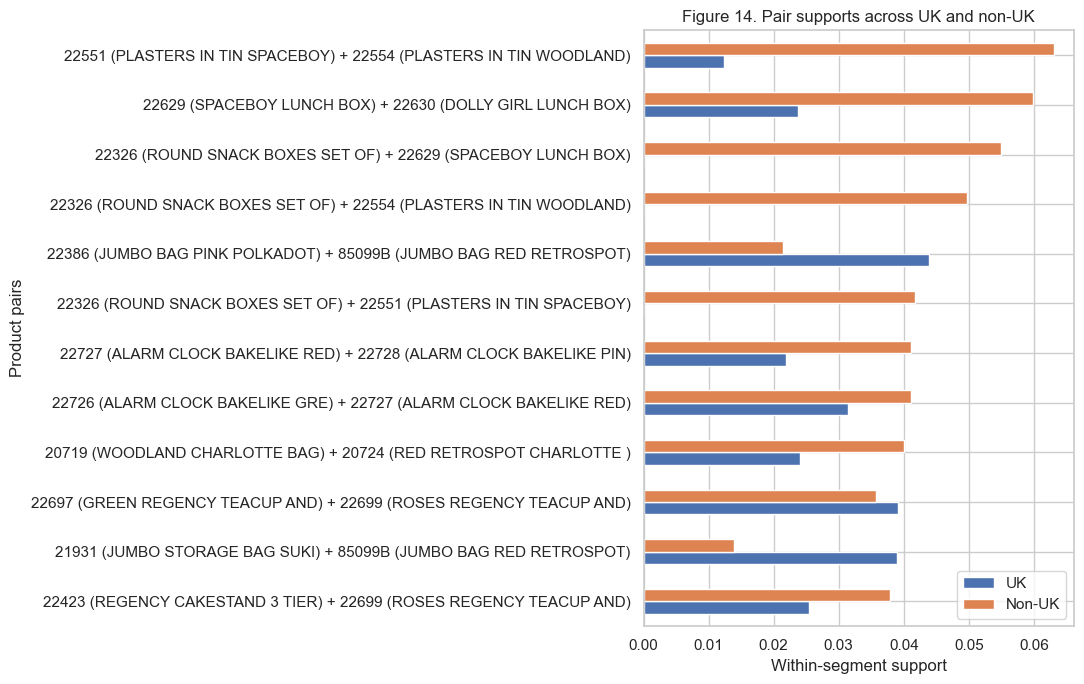

In [33]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
# One figure with two panels: contrasts sizes and rules simultaneously.
axes[0].bar(segment_table['region'],segment_table['transactions'])
axes[0].set(title='Transactions by segment',ylabel='Invoices')
axes[1].bar(segment_table['region'],segment_table['rules_conf_ge_0.3'])
axes[1].set(title='Rules with confidence >= 30%',ylabel='Rules')
fig.suptitle('Figure 13. UK vs non-UK mining comparison')
plt.tight_layout();plt.show()

pair_support={}
for region in ['UK','Non-UK']:
    fr=segment_results[region]
    pair_support[region] = {frozenset(s):v for s,v in zip(fr['itemsets'],fr['support']) if len(s)==2}
combined_pairs = sorted(set(pair_support['UK']) | set(pair_support['Non-UK']),
                       key=lambda s:max(pair_support['UK'].get(s,0),pair_support['Non-UK'].get(s,0)),reverse=True)[:12]
comp=pd.DataFrame({'pair':[fmt_itemset(s) for s in combined_pairs],
                  'UK':[pair_support['UK'].get(s,0) for s in combined_pairs],
                  'Non-UK':[pair_support['Non-UK'].get(s,0) for s in combined_pairs]})
display(comp)
fig,ax=plt.subplots(figsize=(11,7))
if not comp.empty:
    comp.set_index('pair')[['UK','Non-UK']].iloc[::-1].plot(kind='barh',ax=ax)
else:
    ax.text(.5,.5,'No pairs at selected support threshold',ha='center',va='center',transform=ax.transAxes)
ax.set(title='Figure 14. Pair supports across UK and non-UK',xlabel='Within-segment support',ylabel='Product pairs')
plt.tight_layout();plt.show()

<div style="font-family: Arial, sans-serif;
            line-height: 1.7;
            color: #333333;
            font-size: 14px;">

  <h3 style="font-size: 18px;
             font-weight: 700;
             color: #243B53;
             margin-bottom: 12px;">
    Visualizations 13–14 — Interpretation
  </h3>

  <p>
    <strong>Figure 13:</strong> The UK accounts for
    <strong>17,902 transactions</strong> and generates
    <strong>1,424 association rules</strong>, compared with
    1,872 transactions and 716 rules in the Non-UK segment.
    This reflects the substantial difference in market size.
  </p>

  <p>
    <strong>Figure 14:</strong> Product preferences vary across regions.
    The <strong>JUMBO BAG PINK POLKADOT and JUMBO BAG RED RETROSPOT</strong>
    combination is more common in UK transactions
    (<strong>4.39% vs. 2.14%</strong>).
    In contrast, <strong>SPACEBOY and WOODLAND PLASTERS</strong>
    are more frequently purchased together in Non-UK transactions
    (<strong>6.30% vs. 1.24%</strong>).
  </p>

  <p>
    These differences suggest opportunities for
    <strong>region-specific product bundles and marketing campaigns</strong>.
    However, Non-UK results should be interpreted cautiously
    because the segment contains fewer transactions and combines
    customers from multiple countries.
  </p>

  <hr style="border: none;
             border-top: 1px solid #D0D5DD;
             margin: 18px 0 16px 0;">

</div>

## IV.2 Five Evidence-Based Product Bundle Recommendations

**Method:** We select up to five product pairs based on support, confidence, and lift. These metrics help us find products that are often bought together.

We suggest possible discounts for these bundles. However, association rules cannot tell us whether discounts will increase sales. A/B testing can help us check their actual impact (Kohavi et al., 2009).

**Expected Impact:** These bundles may help increase cross-selling and basket value, but the results need to be tested before implementation.

In [34]:
if not filtered_rules.empty:
    b=filtered_rules.copy()
    b['pair_key']=b.apply(lambda r:tuple(sorted(r['antecedents'] | r['consequents'])),axis=1)
    b=b.sort_values(['support','lift','confidence'],ascending=False).drop_duplicates('pair_key')
    b['candidate_score']=b['support']*b['confidence']*np.log1p(b['lift'])
    b=b.sort_values('candidate_score',ascending=False).head(5).copy()
    b['bundle_products']=b['pair_key'].map(fmt_itemset)
    b['proposed_discount_pct']=[5, 5, 10, 10, 5][:len(b)]  # test scenarios, NOT learned optimum
    b['impact_hypothesis']='Test uplift in attachment rate, order value, and gross margin versus control'
    bundles=b[['bundle_products','support','confidence','lift','proposed_discount_pct','impact_hypothesis']].reset_index(drop=True)
else:
    bundles=pd.DataFrame(columns=['bundle_products','support','confidence','lift','proposed_discount_pct','impact_hypothesis'])
display(bundles)
print(f'Qualified evidence-backed candidate bundles: {len(bundles)} / 5 requested')
if len(bundles)<5:
    print('Not enough qualified pairs: explore a lower mining threshold, larger MAX_ITEMS, or broader bundle criteria, and disclose changes.')

,bundle_products,support,confidence,lift,proposed_discount_pct,impact_hypothesis
0,22697 (GREEN REGENCY TEACUP AND) + 22699 (ROSES REGENCY TEACU...,0.038788,0.720188,14.058236,5,"Test uplift in attachment rate, order value, and gross margin..."
1,22698 (PINK REGENCY TEACUP AND ) + 22699 (ROSES REGENCY TEACU...,0.030242,0.781699,14.513918,5,"Test uplift in attachment rate, order value, and gross margin..."
2,22697 (GREEN REGENCY TEACUP AND) + 22698 (PINK REGENCY TEACUP...,0.031961,0.623889,16.126523,10,"Test uplift in attachment rate, order value, and gross margin..."
3,23300 (GARDENERS KNEELING PAD C) + 23301 (GARDENERS KNEELING ...,0.027612,0.720317,15.600811,10,"Test uplift in attachment rate, order value, and gross margin..."
4,22726 (ALARM CLOCK BAKELIKE GRE) + 22727 (ALARM CLOCK BAKELIK...,0.032366,0.653061,12.286996,5,"Test uplift in attachment rate, order value, and gross margin..."


Qualified evidence-backed candidate bundles: 5 / 5 requested


<div style="font-family: Arial, sans-serif;
            line-height: 1.7;
            color: #333333;
            font-size: 14px;">

  <h3 style="font-size: 18px;
             font-weight: 700;
             color: #243B53;
             margin-bottom: 12px;">
    Product Bundle Recommendations — Interpretation
  </h3>

  <p>
    Five product bundles were identified using
    <strong>support, confidence, and lift</strong>.
    The Regency teacup combinations show particularly strong
    associations, with lift values between
    <strong>14.06 and 16.13</strong>.
  </p>

  <p>
    Other promising bundles include matching
    <strong>gardening kneeling pads</strong> and
    <strong>retro alarm clocks</strong>.
    Proposed discounts of <strong>5–10%</strong>
    could be tested to encourage cross-selling
    and increase average order value.
  </p>

  <p>
    These discounts are preliminary recommendations rather
    than proven optimal prices. Their effectiveness should
    be evaluated through promotional experiments and
    profitability analysis.
  </p>

  <hr style="border: none;
             border-top: 1px solid #D0D5DD;
             margin: 18px 0 16px 0;">

</div>

<h2 style="font-weight: bold;">IV.3 Business Interpretation and Practical Applications</h2>

1. **Key Findings**

This data analysis based on the Online Retail dataset found 19,774 transactions and 3,804 products, generating approximately £10.26 million in revenue. It's important consider the significance of the United Kingdom since this region accounted for 85.2% of total revenue.

After performing the analysis of frequent product itemsets, it was observed that increasing the minimum support threshold from 1% to 5% reduced the number of frequent itemsets from 1,033 to 36. At a 2% support threshold, the analysis identified 212 frequent itemsets, including 89 product pairs and 3 product triples purchased together. This test showed the importance of testing different thresholds and helped to identify a broader range of product combinations.

It’s important to point out that the 1% support threshold identified the largest number of frequent itemsets (1,033), while the 5% threshold highlighted only the most frequent combinations. Therefore, both the 1% and 5% thresholds provided different and relevant findings.

2. **Cross-Selling**
   
Product associations are widely used because they support recommendations for complementary products and help identify cross-selling opportunities. Using an example from this dataset, the results show that the rule GREEN REGENCY TEACUP AND SAUCER → ROSES REGENCY TEACUP AND SAUCER reached 72.02% confidence and a lift of 14.06, indicating a strong positive association between these products. Another valuable combination for cross-selling was also found: PINK REGENCY TEACUP AND SAUCER → ROSES REGENCY TEACUP AND SAUCER, with 3.02% support, 78.17% confidence, and a lift of 14.51. These findings suggest that recommending associated products could create additional purchasing opportunities and help increase the average order value.

However, a high lift does not guarantee that customers will respond to recommendations or purchase the suggested bundles. The company should test these recommendations before implementing them on a larger scale.

3. **Inventory Implications**

Frequently purchased-together products should be considered when planning stock levels and replenishment. Monitoring associated products together may help reduce missed sales opportunities caused by stockouts.

4. **Marketing Recommendations**

This data-driven analysis, it can be concluded that the company should use association rules to develop cross-selling strategies for its customers, focusing mainly on prioritizing product combinations based on support, confidence, and lift values.

This could help with (i) personalized recommendations for customers, (ii) dynamic product bundle recommendations, and (iii) targeted and specific promotional campaigns. Evaluating performance through (i) conversion rates, (ii) average order value, (iii) incremental revenue, (iv) gross margin, and (v) return on investment could help transform purchasing patterns into more effective marketing decisions.

Since there is a considerable difference between transactions in the UK and other regions, region-specific marketing strategies could be used. This approach could potentially increase transaction volume compared with using a single marketing strategy for the entire company and all regions.

5. **Regional Strategy**

The UK accounted for 85.2% of total revenue, which shows that the company should prioritize this region in its business strategy. We also noticed variations in product associations inside and outside the UK, meaning that purchasing patterns differ across regions. Therefore, the company should consider adapting its promotional strategies and campaigns for both areas. For example, the JUMBO BAG PINK POLKADOT and JUMBO BAG RED RETROSPOT combination had a higher support in the UK (4.39%) than in non-UK markets (2.14%). On the other hand, SPACEBOY and WOODLAND PLASTERS were more strongly associated outside the UK (6.30%) compared to the UK (1.24%). A strategy like cross-selling could help the company boost sales by providing region-specific recommendations.


6. **Methodological Limitations**:

The transaction matrix used the 120 most frequent products in the dataset, and for the analysis only positive and valid purchases were considered; cancelled transactions and records with invalid quantities or prices were excluded from this analysis. It was also found that there are many missing values in the Customer ID variable, but it should be noted that these missing values are not relevant for product-level association analysis. It is also highlighted that association rules are sensitive to support and confidence thresholds, and the observed relationships do not establish causality.

In [35]:
# Compact final consistency check (run this last)
assert len(transactions)==basket_stats.shape[0]
assert set(SUPPORT_THRESHOLDS).issubset(frequent_by_support)
assert set(CONFIDENCE_THRESHOLDS)==set(pd.DataFrame(rule_counts)['min_confidence'])
assert set(segment_results)=={'UK','Non-UK'}
print('Notebook validation complete. Figures 1–14 were defined above.')
print('Dataset row count:',len(raw),'| valid sales lines:',len(df),'| transaction baskets:',len(transactions))
print('Candidate bundles:',len(bundles))

Notebook validation complete. Figures 1–14 were defined above.
Dataset row count: 541909 | valid sales lines: 522569 | transaction baskets: 19774
Candidate bundles: 5


## References

Agrawal, R., & Srikant, R. (1994). Fast algorithms for mining association rules in large databases. *Proceedings of the 20th International Conference on Very Large Data Bases (VLDB)*, 487–499. https://rsrikant.com/papers/vldb94.pdf

Chen, D. (2015). *Online Retail* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

Kohavi, R., Longbotham, R., Sommerfield, D., & Henne, R. M. (2009). Controlled experiments on the web: Survey and practical guide. *Data Mining and Knowledge Discovery, 18*, 140–181. https://doi.org/10.1007/s10618-008-0114-1

Raschka, S. (n.d.). *Association rules*. mlxtend Documentation. https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/